# MIT 6.5940 · Lab 0：在本地训练第一个图像分类模型

你会用 PyTorch 训练一个模型，让它从小图片中识别飞机、猫、卡车等 10 个类别。跟着做一遍：**读图片 → 组成一批 → 算分类分数 → 用错误更新模型 → 检查预测**。

先保持默认的 `quick` 模式。从上往下读，每次按 **Shift+Enter** 运行一格。代码格共享变量；遇到 `NameError`，先检查前面的格子是不是漏跑了。改配置后，重启内核，再从头运行。

改编自同目录下的原版 MIT 6.5940 *TinyML and Efficient AI Computing* [Lab 0](lab0.ipynb)。本地环境的安装步骤见 [README](README.md)。

## 1. 准备环境

在 VS Code 右上角选择 `lab0/.venv/Scripts/python.exe`。运行下面的代码后，核对打印出来的 Python 路径。

`from ... import ...` 是从一个模块里取出要用的名字。例如 `nn` 提供搭神经网络的零件，`DataLoader` 帮我们把单张图片组成一批。

In [1]:
import random  # 导入 Python 自带的随机数模块，后面用 random.Random 抽取数据。
import sys  # 导入系统模块，后面用 sys.executable 查看当前 Python 解释器的位置。
from pathlib import Path  # 从 pathlib 模块中引入 Path 类，后面直接用 Path 操作文件和目录路径。

import matplotlib.pyplot as plt  # 导入 Matplotlib 的 pyplot 模块并起别名 plt，后面用 plt 绘图。
import numpy as np  # 导入 NumPy 并起别名 np，后面用 np.interp 计算学习率的变化。
import torch  # 导入 PyTorch，后面用 torch 创建张量、选择设备和控制梯度计算。
from torch import nn  # 从 torch 中引入 nn 模块，后面用 nn.Conv2d 等名称创建神经网络层。
from torch.optim import SGD  # 从 torch.optim 中直接引入 SGD 优化器类，使用时写 SGD(...)。
from torch.optim.lr_scheduler import LambdaLR  # 引入 LambdaLR 类，用自定义函数调整优化器的学习率。
from torch.utils.data import DataLoader, Subset  # 引入 DataLoader（按批读取数据）和 Subset（按索引选取数据子集）。
from torchprofile import profile_macs  # 引入 profile_macs 函数，用来估算模型前向计算的乘加运算次数。
from torchvision import transforms  # 引入 transforms 模块，后面用它裁剪、翻转图片并转换为张量。
from torchvision.datasets import CIFAR10  # 引入 CIFAR10 数据集类，负责读取 CIFAR-10 图片和标签。
from torchvision.datasets.utils import download_and_extract_archive  # 引入下载并解压数据包的工具函数，后面直接用函数名调用。

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # 条件表达式：CUDA 可用就选 NVIDIA GPU，否则选 CPU；device 保存设备信息。
if device.type == "cpu":  # 如果最终选用的是 CPU，就执行下面缩进的代码。
    # 小模型不一定能从更多 CPU 线程获益；限制线程数以减少开销。
    torch.set_num_threads(min(4, torch.get_num_threads()))  # 读取当前线程数并限制为最多 4 个，减少这个小模型在 CPU 上的线程调度开销。

lab_dir = Path.cwd()  # 取得内核当前的工作目录；它不一定就是 notebook 文件所在的目录。
if (lab_dir / "lab0" / "lab0_local.ipynb").is_file():  # 用 / 拼接路径，判断当前目录下面是否有 lab0/lab0_local.ipynb 文件。
    lab_dir = lab_dir / "lab0"  # 如果从项目根目录启动，就把 lab_dir 调整为其下的 lab0 目录。
if not (lab_dir / "lab0_local.ipynb").is_file():  # 再次检查是否找到了目标 notebook；not 表示对判断结果取反。
    raise FileNotFoundError("请从 Course-TinyML 或 lab0 目录启动笔记本。")  # 找不到文件就抛出异常并停止当前单元格，提示从正确的目录启动。

data_dir = lab_dir / "data" / "cifar10"  # 拼接 CIFAR-10 的本地保存路径；这里只构造路径，不会立即下载数据。

print(f"Python: {sys.executable}")  # f 字符串把花括号中的值嵌入文字，打印当前实际运行的 Python 路径。
print(f"PyTorch: {torch.__version__} | Device: {device}")  # 打印 PyTorch 版本和计算设备，确认是否使用了预期环境。
print(f"Data: {data_dir}")  # 打印数据保存路径，便于查找已下载的数据。

Python: c:\Users\cswof\.conda\envs\AI\python.exe
PyTorch: 2.6.0+cu126 | Device: cuda
Data: e:\SKILLS\Course-TinyML\lab0\data\cifar10


### 选择练习模式

`quick`：用较窄的 VGG、2,048 张训练图和 1,000 张测试图，先走完整个流程。  
`course`：使用原课的 VGG、完整 CIFAR-10 和 20 轮训练，建议在有 CUDA 的环境里尝试。

同一个随机种子有助于复现实验；不同硬件或软件版本仍可能产生不同结果。

In [2]:
mode = "course"  # 设置运行模式；先用 quick 跑通流程，再考虑改为 course。
seed = 0  # 设置随机种子，作为后续随机操作的初始值。
torch.manual_seed(seed)  # 设置 PyTorch 的随机种子，帮助复现参数初始化和随机数据处理；不保证所有环境结果完全相同。

if mode == "quick":  # 如果选择 quick 模式，就使用下面较小的模型和数据量。
    architecture = [16, 32, "M", 64, 64, "M", 64, 64, "M", 64, 64, "M"]  # 定义各层配置：整数是卷积层输出通道数，M 表示一次最大池化。
    train_limit, test_limit = 2048, 1000  # 同时给两个变量赋值：取 2048 张训练图片和 1000 张测试图片。
    batch_size, num_epochs, base_lr = 64, 3, 0.05  # 依次设置每批 64 张、训练 3 轮、基础学习率 0.05。
elif mode == "course":  # 否则，如果选择 course 模式，就使用下面的课程配置。
    architecture = [64, 128, "M", 256, 256, "M", 512, 512, "M", 512, 512, "M"]  # 使用更多输出通道的模型；M 仍然表示最大池化层。
    train_limit, test_limit = None, None  # None 表示不限制训练集和测试集的数量，使用完整数据。
    batch_size, num_epochs, base_lr = 512, 20, 0.4  # 依次设置每批 512 张、训练 20 轮、基础学习率 0.4。
else:  # 如果两个模式都不匹配，就进入这个分支。
    raise ValueError('mode 只能是 "quick" 或 "course"。')  # 抛出配置错误，避免拼错模式名后继续运行。

print(f"模式：{mode}；每批 {batch_size} 张图；训练 {num_epochs} 轮")  # 打印本次使用的模式、批大小和训练轮数。

模式：course；每批 512 张图；训练 20 轮


## 2. 认识数据和张量

[CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) 的每张图有 3 个颜色通道，大小是 32×32。每个标签是 0 到 9 的整数，代表一个类别。

模型在**训练集**上学习；**测试集**的图片不参与参数更新。训练时随机裁剪和水平翻转，让模型见到同一物体的不同样子；测试时只用 `ToTensor()`，把图片变成 PyTorch 可以计算的数字数组。

第一次会从 [MIT 课程镜像](https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python) 下载并校验约 163 MiB 的数据包。两种模式共用本地缓存。

In [3]:
if not (data_dir / CIFAR10.base_folder / "batches.meta").is_file():  # 检查解压后的类别信息文件是否存在；缺少时进入下载流程。
    download_and_extract_archive(  # 调用下载及解压函数，具体参数写在下面几行。
        url="https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/main/cifar-10-python.tar.gz",  # 指定课程镜像中的数据包地址；url 是函数的一个关键字参数。
        download_root=str(data_dir),  # 把 Path 转为字符串，指定数据包的下载和解压目录。
        filename=CIFAR10.filename,  # 使用 CIFAR10 类提供的标准压缩包文件名。
        md5=CIFAR10.tgz_md5,  # 使用数据包的 MD5 校验值检查下载内容是否完整。
    )  # 结束下载函数调用；只有上面的 if 条件成立时才会执行它。

train_transform = transforms.Compose([  # 把列表里的图片变换按顺序组合成一个处理流程。
    transforms.RandomCrop(32, padding=4),  # 先在四周各补 4 个像素，再随机裁剪成 32×32，增加训练图片的位置变化。
    transforms.RandomHorizontalFlip(),  # 随机左右翻转图片，增加训练样本的变化。
    transforms.ToTensor(),  # 把图片转为张量；这里的像素从 0～255 缩放到 0～1，形状变为 [通道, 高, 宽]。
])  # 结束变换列表和 Compose 调用。
train_data = CIFAR10(data_dir, train=True, transform=train_transform)  # 读取训练集，并在每次取图片时应用上面定义的随机变换。
test_data = CIFAR10(data_dir, train=False, transform=transforms.ToTensor())  # 读取测试集；只转成张量，保持测试输入不受随机裁剪和翻转影响。
class_names = test_data.classes  # 取得类别名称列表；例如 class_names[0] 是 airplane，标签整数可用作列表索引。


def take_subset(dataset, limit):  # 定义选取数据子集的函数；dataset 是数据集，limit 是最多取多少张。
    if limit is None:  # 用 is None 判断是否没有设置数量限制。
        return dataset  # 没有限制就直接返回原数据集，不进行抽样。
    # sample 从索引中不重复地抽取，Subset 保留对原数据的引用。
    indices = random.Random(seed).sample(range(len(dataset)), limit)  # 创建一个固定种子的随机数生成器，从所有索引中抽取 limit 个不重复的索引。
    return Subset(dataset, indices)  # 用这些索引构造子集；保留对原数据集的引用，不复制整套图片。


train_subset = take_subset(train_data, train_limit)  # 根据 train_limit 取得本次训练使用的数据。
test_subset = take_subset(test_data, test_limit)  # 根据 test_limit 取得本次测试使用的数据。
print(f"训练：{len(train_subset):,} 张；测试：{len(test_subset):,} 张")  # len 计算子集大小；格式符 :, 让数字用千位分隔符显示。

训练：50,000 张；测试：10,000 张


### 每个类别看一张图

`enumerate(class_names)` 同时给出类别编号和名字。取出一张图片后，`image.permute(1, 2, 0)` 把 `[通道, 高, 宽]` 换成绘图库需要的 `[高, 宽, 通道]`，像素值没有改变。

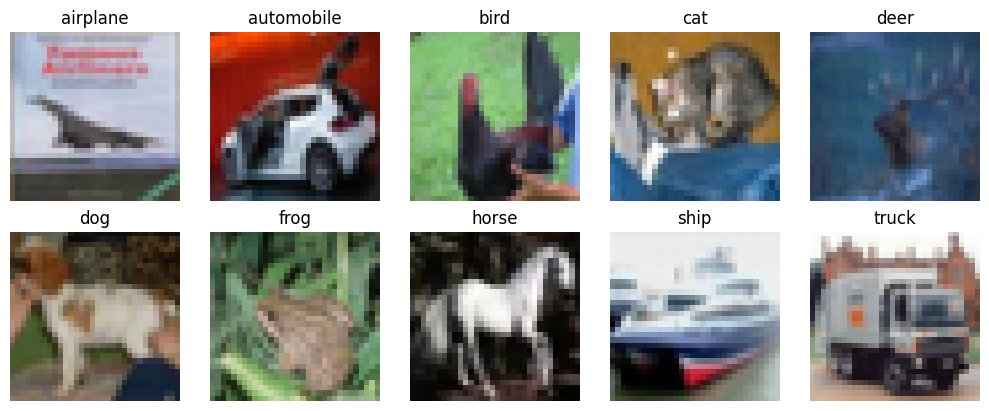

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4), layout="constrained")  # 创建 2 行 5 列子图；fig 是整张图，axes 是子图数组；figsize 的单位是英寸，layout 自动调整间距。
for label, name in enumerate(class_names):  # enumerate 同时给出类别编号 label 和类别名 name，依次展示每个类别。
    index = test_data.targets.index(label)  # 在测试标签列表中，找到当前类别第一次出现的位置。
    image, _ = test_data[index]  # 读取该位置的图片和标签；此处用 _ 接收不再使用的标签。
    axis = axes.flat[label]  # axes.flat 按顺序访问二维子图数组，用类别编号选出一个子图。
    axis.imshow(image.permute(1, 2, 0))  # 把图片从 [通道, 高, 宽] 调整为绘图需要的 [高, 宽, 通道] 并显示。
    axis.set_title(name)  # 把当前类别名设为该子图的标题。
    axis.axis("off")  # 隐藏坐标轴及刻度，让图片更清楚。
plt.show()  # 显示整张图，查看各类别的示例图片。

### 把图片组成一批（batch）

训练时打乱顺序，让每轮的批次组合不固定。Windows 下先用 `num_workers=0`，让主进程负责取数据。

运行后看两个形状：图片是 `[B, 3, 32, 32]`，标签是 `[B]`。`B` 是这批的图片数。试着猜一猜 `images[0].shape` 与 `labels[0].item()` 各代表什么。

In [5]:
train_loader = DataLoader(  # 创建训练数据加载器，让训练数据可以按批次读取。
    train_subset, batch_size=batch_size, shuffle=True, num_workers=0  # 指定训练子集和每批数量；shuffle=True 每次遍历时打乱顺序，num_workers=0 在主进程读取。
)  # 结束训练数据加载器的创建。
test_loader = DataLoader(  # 创建测试数据加载器，用于分批评估模型。
    test_subset, batch_size=batch_size, shuffle=False, num_workers=0  # 指定测试子集；测试时保持顺序，主进程读取数据。
)  # 结束测试数据加载器的创建。

# iter(...) 创建迭代器；next(...) 从中拿一批。
images, labels = next(iter(train_loader))  # 先创建训练加载器的迭代器，再取第一批，拆分得到图片张量和标签张量。
print(f"images: {tuple(images.shape)}, {images.dtype}")  # 打印图片张量的形状与类型；通常是 [批大小, 3, 32, 32] 和 float32。
print(f"labels: {tuple(labels.shape)}, {labels.dtype}")  # 打印标签张量的形状与类型；通常是 [批大小] 和 int64。
print(f"第 1 张图片的类别：{class_names[labels[0].item()]}")  # 取第一个标签，用 item() 转为 Python 整数，再查出对应类别名。

images: (512, 3, 32, 32), torch.float32
labels: (512,), torch.int64
第 1 张图片的类别：deer


## 3. 搭建模型：图片 → 10 个分类分数

沿用原课的 [VGG](https://arxiv.org/abs/1409.1556) 变体。配置里的数字代表卷积输出多少个通道；`"M"` 代表最大池化，把高和宽各减半。卷积提取图像特征，BatchNorm 调整中间特征的分布，ReLU 把负值变成 0。

- `__init__` 定义有哪些层；`self` 指这个模型对象，写成 `self.backbone` 就能在别的方法里使用它。
- `forward` 定义一批图片流过这些层的顺序。调用 `model(images)` 时，PyTorch 会执行这条计算路径。
- 四次最大池化将 32×32 变成 2×2。对每个通道的 2×2 区域取平均，再用线性层得到 10 个分数（**logits**）。

In [6]:
class VGG(nn.Module):  # 定义 VGG 模型类，继承 nn.Module，从而支持 PyTorch 的参数管理等功能。
    def __init__(self, architecture, num_classes):  # 构造函数在创建模型时执行；self 代表当前模型，另外两个参数是层配置和类别数。
        super().__init__()  # 调用父类的初始化方法，让 nn.Module 先完成必要的内部设置。
        layers = []  # 创建空列表，按顺序存放稍后建立的网络层。
        in_channels = 3  # 输入图片是 RGB，因此最初的输入通道数为 3。

        for width in architecture:  # 依次读取配置中的每一项，width 可能是通道数，也可能是字符串 M。
            if width == "M":  # 判断当前配置项是否表示最大池化。
                layers.append(nn.MaxPool2d(2))  # 添加 2×2 最大池化层，默认步长为 2，把特征图的高、宽各减半。
            else:  # 配置项不是 M 时，把它当作卷积层的输出通道数。
                layers.extend([  # extend 把列表里的多个层依次加入 layers；append 则是添加单个对象。
                    nn.Conv2d(in_channels, width, kernel_size=3, padding=1, bias=False),  # 添加 3×3 卷积；padding=1 保持高宽，bias=False 表示不单独学习卷积偏置。
                    nn.BatchNorm2d(width),  # 按输出通道添加批量归一化层；训练时用当前批次统计量，评估时用运行统计量。
                    nn.ReLU(inplace=True),  # 添加 ReLU 激活，把负数变为 0；inplace=True 表示在原张量上修改以节省部分内存。
                ])  # 结束本组网络层的列表和 extend 调用。
                in_channels = width  # 把本层输出通道数记为下一层的输入通道数。

        self.backbone = nn.Sequential(*layers)  # 按顺序组合这些层；*layers 把列表展开为多个位置参数，self 让其他方法也能访问它。
        self.classifier = nn.Linear(in_channels, num_classes)  # 创建全连接分类层，把每张图的 in_channels 个特征映射成 num_classes 个分数。

    def forward(self, images):  # 定义前向计算方法；调用 model(images) 时，PyTorch 会通过模块调用流程执行它。
        features = self.backbone(images)  # 提取图像特征；当前配置经过四次池化，形状由 [B, 3, 32, 32] 变为 [B, C, 2, 2]。
        pooled = features.mean(dim=(2, 3))  # 对维度 2、3（高、宽）求平均，得到每张图的 C 个特征，形状为 [B, C]。
        logits = self.classifier(pooled)  # 用分类层计算各类的原始分数 logits，形状为 [B, 10]，这些分数还不是概率。
        return logits  # 返回原始分类分数，供损失函数或预测步骤使用。


model = VGG(architecture, num_classes=len(class_names)).to(device)  # 按配置创建模型，类别数取类别列表长度，并把模型参数移到选定设备。

### 自检 1.1：跟着形状走一遍

原课练习要求你补全 `forward`。上面给了可运行示例，建议先遮住那三行，自己说出「提取特征 → 平均高和宽 → 产生类别分数」，再试着重写。下面的 `assert` 会在输出形状不对时停下来。

In [7]:
example = torch.zeros(1, 3, 32, 32, device=device)  # 创建一张全零测试图片；四个维度依次为批大小、RGB 通道数、高和宽，并放到选定设备。
model.eval()  # 切换为评估模式，让 BatchNorm 使用已记录的统计量；这一步本身不会关闭梯度记录。
with torch.inference_mode():  # 在这个缩进块内关闭梯度等推理时不需要的记录，减少计算和内存开销。
    feature_map = model.backbone(example)  # 只运行特征提取部分，查看分类之前的特征图。
    logits = model(example)  # 运行完整模型，得到这张测试图片的 10 个原始分类分数。

print("特征形状:", tuple(feature_map.shape))  # 打印特征图的形状；tuple 将形状转为普通元组显示。
print("分类分数形状:", tuple(logits.shape))  # 打印分类输出形状，确认批大小与类别数。
assert logits.shape == (1, 10)  # 断言输出形状必须为 [1, 10]；不满足时抛出 AssertionError，帮助发现模型结构问题。

特征形状: (1, 512, 2, 2)
分类分数形状: (1, 10)


### 模型有多大？做一次预测要算多少？

**参数量**是模型中可训练数字的个数，像是有多少个能动的旋钮。**MACs** 是乘加运算次数的估算，这里用 [TorchProfile](https://github.com/zhijian-liu/torchprofile) 统计一张 32×32 图片的前向计算开销；它和实际耗时不是一回事。

In [8]:
num_params = 0  # 把可训练参数总数初始化为 0，后面逐个累加。
for parameter in model.parameters():  # 遍历模型的各个参数张量；一个张量通常包含很多个数值。
    if parameter.requires_grad:  # 只统计 requires_grad=True、允许通过梯度更新的参数。
        num_params += parameter.numel()  # numel() 返回张量内元素总数，把它加到可训练参数总数中。

# 用 eval 模式统计，避免改变 BatchNorm 在训练中记录的统计量。
# example[:1] 只取第一张，保证统计的是单张图片的开销。
with torch.inference_mode():  # 在不记录梯度的上下文中估算运算量；模型继续保持前面设置的 eval 模式。
    num_macs = profile_macs(model, example[:1])  # 估算单张图片前向计算的乘加次数；[:1] 保留批次维度并只取第一张图片。
print(f"Trainable parameters: {num_params:,}")  # 打印可训练参数个数；:, 表示使用千位分隔符。
print(f"MACs per image: {num_macs:,}")  # 打印每张图片的 MACs 估算值；这是运算量指标，不是实际耗时。

Trainable parameters: 9,228,362
MACs per image: 606,164,480


## 4. 决定模型怎样学习

**损失（loss）**衡量模型在一批图上猜得有多差。分类用交叉熵：给对的类别更高的相对分数，损失一般会更小。PyTorch 的 `CrossEntropyLoss` 直接接收 logits 和整数标签。

**梯度**告诉我们改动参数会怎样影响损失；**优化器**据此更新参数。**学习率**决定更新时迈多大一步。和原课一样，学习率先线性升高，再逐步降到 0；这里的横轴是更新步数，一批图片对应一步。

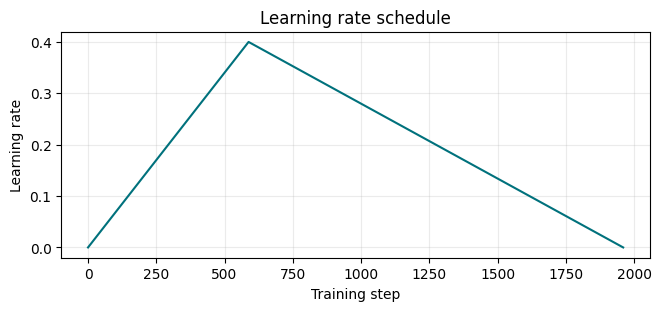

In [9]:
criterion = nn.CrossEntropyLoss()  # 创建交叉熵损失函数，直接接收模型的 logits 和整数类别标签，无需先手动 softmax。
optimizer = SGD(model.parameters(), lr=base_lr, momentum=0.9, weight_decay=5e-4)  # 创建随机梯度下降优化器；lr 是基础学习率，momentum 累积更新方向，weight_decay 添加参数衰减。
total_steps = len(train_loader) * num_epochs  # 每轮的批次数乘训练轮数，得到总更新步数；len(train_loader) 是批次数。


def lr_multiplier(step):  # 定义函数：输入当前训练步数，返回基础学习率的乘数。
    # np.interp 在三个已知点之间做线性插值：开始、30% 处、结束。
    return float(np.interp(step, [0, total_steps * 0.3, total_steps], [0.0, 1.0, 0.0]))  # 在起点、30% 处和终点之间做线性插值，乘数从 0 升到 1 再降到 0；float 转为 Python 浮点数。


scheduler = LambdaLR(optimizer, lr_lambda=lr_multiplier)  # 创建学习率调度器；实际学习率等于基础学习率乘 lr_multiplier 返回的值，初始乘数是 0。
steps = range(total_steps + 1)  # 生成从 0 到 total_steps 的步数；range 的右端不包含在内，所以这里加 1。
fig, axis = plt.subplots(figsize=(6.5, 3), layout="constrained")  # 创建学习率曲线的画布和单个子图，并自动调整边距。
axis.plot(steps, [base_lr * lr_multiplier(step) for step in steps], color="#00717c")  # 列表推导式逐步计算实际学习率，再以步数为横轴画线；color 指定颜色。
axis.set(title="Learning rate schedule", xlabel="Training step", ylabel="Learning rate")  # 设置标题、横轴名称和纵轴名称。
axis.grid(alpha=0.25)  # 添加透明度为 0.25 的网格，方便读数。
plt.show()  # 显示学习率变化曲线。

## 5. 训练、评估和读结果

一 **epoch** 就是把训练集完整走一遍。每批重复四件事：① 清空上一批梯度；② 前向计算分数和损失；③ 反向计算梯度；④ 更新参数。用 `def` 把整轮写成函数，就能在外层循环里重复调用。

评估函数只做前向计算。`model.eval()` 切换 BatchNorm 的行为；`torch.inference_mode()` 关掉这里用不到的梯度记录。

In [10]:
def train_one_epoch(model, loader, criterion, optimizer, scheduler):  # 定义训练一轮的函数，把模型、数据加载器、损失函数、优化器和调度器作为参数传入。
    model.train()  # 切换到训练模式，让 BatchNorm 使用当前批次的统计量并更新运行统计量。
    total_loss = 0.0  # 初始化这一轮累计的损失总和。
    num_samples = 0  # 初始化这一轮处理过的图片总数。

    for images, labels in loader:  # 从加载器中逐批取数据，并拆分成图片和对应标签。
        images = images.to(device)  # 把这一批图片移到前面选定的 CPU 或 GPU。
        labels = labels.to(device)  # 把标签也移到同一设备，保证它能和模型输出一起参与计算。

        optimizer.zero_grad()  # 清空上一步留下的梯度；PyTorch 默认会累积梯度，因此每批更新前都要清理。
        logits = model(images)  # 前向计算：把图片输入模型，取得每张图对应的各类别分数。
        loss = criterion(logits, labels)  # 根据原始分类分数与真实标签，计算这一批的平均交叉熵损失。
        loss.backward()  # 反向传播，计算损失对各个可训练参数的梯度。
        optimizer.step()  # 让优化器依据梯度、当前学习率等设置更新模型参数。
        scheduler.step()  # 推进学习率调度器，为下一批参数更新设置学习率。

        batch_count = labels.size(0)  # 读取标签张量第 0 维的长度，也就是这一批实际有多少张图。
        total_loss += loss.item() * batch_count  # item() 提取损失数值，乘图片数恢复该批损失总和，避免较小的最后一批权重过大。
        num_samples += batch_count  # 累加已处理图片数量。

    return total_loss / num_samples  # 用总损失除以总图片数，返回这一轮每张图片的平均损失。


@torch.inference_mode()  # 装饰器：让下面整个 accuracy 函数都在推理模式下执行，不记录梯度。
def accuracy(model, loader):  # 定义准确率评估函数，输入模型和要评估的数据加载器。
    model.eval()  # 切换到评估模式；它与上面的 inference_mode 分别负责层的行为和梯度记录。
    num_correct = 0  # 初始化预测正确的图片总数。
    num_samples = 0  # 初始化参与评估的图片总数。

    for images, labels in loader:  # 逐批读取待评估的图片和真实标签。
        logits = model(images.to(device))  # 把图片移到选定设备，再运行模型，得到形状为 [批大小, 类别数] 的分数。
        # dim=1 是类别所在的轴；每张图片各找一个最大分数的索引。
        predictions = logits.argmax(dim=1)  # 沿类别维度 dim=1 找最大分数的索引，得到每张图预测的类别编号。
        num_correct += (predictions == labels.to(device)).sum().item()  # 逐项比较预测与真实标签；sum() 统计正确个数，item() 转为数值，再累加。
        num_samples += labels.size(0)  # 累加本批图片数，作为准确率的分母。

    return 100 * num_correct / num_samples  # 返回百分比准确率，例如返回 75.0 表示 75%。

### 开始训练

先测量训练前的准确率，之后每轮记录平均训练损失和测试准确率。想再做一轮完整实验，请重启内核并从头运行：训练过的模型和学习率进度都留在内核里。

In [11]:
if scheduler.last_epoch != 0:  # 检查调度器是否已经前进过，防止直接重复运行本单元格而接着旧模型训练。
    raise RuntimeError("这个模型已经开始训练。请重启内核并从头运行。")  # 检测到已开始训练就报错，提示重启内核后从头建立模型、优化器和调度器。

baseline = accuracy(model, test_loader)  # 先评估尚未训练的模型，得到后面比较时使用的基准准确率。
print(f"训练前测试准确率：{baseline:.1f}%", flush=True)  # 打印训练前准确率；:.1f 保留一位小数，flush=True 让文字立即输出。
loss_history = []  # 创建空列表，逐轮保存平均训练损失。
accuracy_history = []  # 创建空列表，逐轮保存测试准确率。

for epoch in range(1, num_epochs + 1):  # 按第 1 轮到第 num_epochs 轮循环；range 的右端需要加 1。
    avg_loss = train_one_epoch(model, train_loader, criterion, optimizer, scheduler)  # 训练完整一轮，并接收该轮的平均损失。
    test_acc = accuracy(model, test_loader)  # 用本轮更新后的模型计算测试准确率。
    loss_history.append(avg_loss)  # 把本轮平均损失追加到历史列表，供后面画图。
    accuracy_history.append(test_acc)  # 把本轮测试准确率追加到历史列表。
    print(f"第 {epoch:>2} / {num_epochs} 轮 | 损失 {avg_loss:.3f} | 测试准确率 {test_acc:.1f}%", flush=True)  # 打印训练进度；:>2 让轮数右对齐，:.3f 和 :.1f 分别保留三位和一位小数。

best_accuracy = max(accuracy_history)  # 在各轮测试准确率中找最大值；这里只记录数值，没有保存该轮的模型参数。
best_epoch = accuracy_history.index(best_accuracy) + 1  # 查找最高准确率第一次出现的列表位置；列表从 0 开始，所以加 1 才是轮数。
print(f"最高的测试准确率出现在第 {best_epoch} 轮：{best_accuracy:.1f}%")  # 打印取得最高测试准确率的轮数和数值；当前 model 仍是最后一轮的模型。

训练前测试准确率：10.0%
第  1 / 20 轮 | 损失 1.494 | 测试准确率 21.9%
第  2 / 20 轮 | 损失 0.981 | 测试准确率 51.7%
第  3 / 20 轮 | 损失 0.794 | 测试准确率 62.7%
第  4 / 20 轮 | 损失 0.671 | 测试准确率 58.4%
第  5 / 20 轮 | 损失 0.598 | 测试准确率 60.7%
第  6 / 20 轮 | 损失 0.554 | 测试准确率 70.6%
第  7 / 20 轮 | 损失 0.499 | 测试准确率 69.1%
第  8 / 20 轮 | 损失 0.441 | 测试准确率 70.8%
第  9 / 20 轮 | 损失 0.394 | 测试准确率 77.6%
第 10 / 20 轮 | 损失 0.363 | 测试准确率 77.9%
第 11 / 20 轮 | 损失 0.341 | 测试准确率 56.3%
第 12 / 20 轮 | 损失 0.305 | 测试准确率 74.8%
第 13 / 20 轮 | 损失 0.279 | 测试准确率 81.0%
第 14 / 20 轮 | 损失 0.242 | 测试准确率 84.8%
第 15 / 20 轮 | 损失 0.211 | 测试准确率 86.2%
第 16 / 20 轮 | 损失 0.175 | 测试准确率 82.8%
第 17 / 20 轮 | 损失 0.138 | 测试准确率 89.0%
第 18 / 20 轮 | 损失 0.102 | 测试准确率 91.1%
第 19 / 20 轮 | 损失 0.067 | 测试准确率 92.2%
第 20 / 20 轮 | 损失 0.041 | 测试准确率 93.2%
最高的测试准确率出现在第 20 轮：93.2%


### 自检 1.2：训练前后有什么变化？

左图看训练损失；右图的第 0 轮是训练前的基准。记录哪一轮测试准确率最高，再比较最后一轮和训练前差多少**个百分点**。快速模式用的数据和模型都更小，结果不能和原课完整训练的准确率直接比较。

这里延续原课用测试集观察每轮的做法。以后如果要凭分数选模型或调参，应另外留一个**验证集**，最后再用测试集评估。

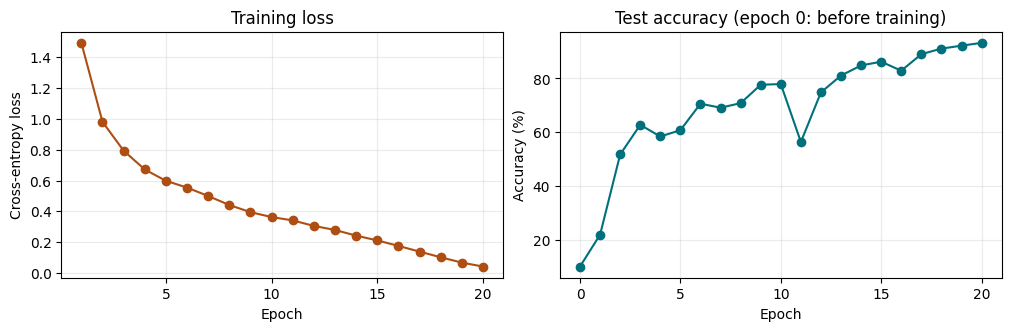

In [12]:
epochs = list(range(1, num_epochs + 1))  # 生成用于横轴的轮数列表：[1, 2, ..., num_epochs]。
fig, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")  # 创建一行两列子图，并分别用 loss_axis 和 accuracy_axis 保存两个绘图区。
loss_axis.plot(epochs, loss_history, color="#ae4e13", marker="o")  # 在左图画各轮训练损失，marker=o 表示用圆点标出每轮数值。
loss_axis.set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")  # 设置左图的标题和坐标轴名称，损失用交叉熵表示。
accuracy_axis.plot([0] + epochs, [baseline] + accuracy_history, color="#00717c", marker="o")  # 把训练前的第 0 轮及基准准确率加在列表前面，在右图画完整的准确率变化。
accuracy_axis.set(title="Test accuracy (epoch 0: before training)", xlabel="Epoch", ylabel="Accuracy (%)")  # 设置右图标题和坐标轴名称，准确率单位为百分比。
for axis in (loss_axis, accuracy_axis):  # 依次处理两个子图，统一设置它们的刻度和网格。
    axis.xaxis.get_major_locator().set_params(integer=True)  # 让横轴的主要刻度尽量使用整数，对应完整训练轮数。
    axis.grid(alpha=0.25)  # 添加较淡的网格，便于比较曲线数值。
plt.show()  # 显示训练损失和测试准确率两张曲线。

## 6. 看看模型猜对了哪些图片

拿测试子集的前 10 张图，用**最后一轮**的模型预测。标题里 `Pred` 是模型的猜测，`True` 是真实标签；`OK` / `MISS` 表示对或错。10 张图能帮你理解错误，不用它们来代替整个测试子集的准确率。

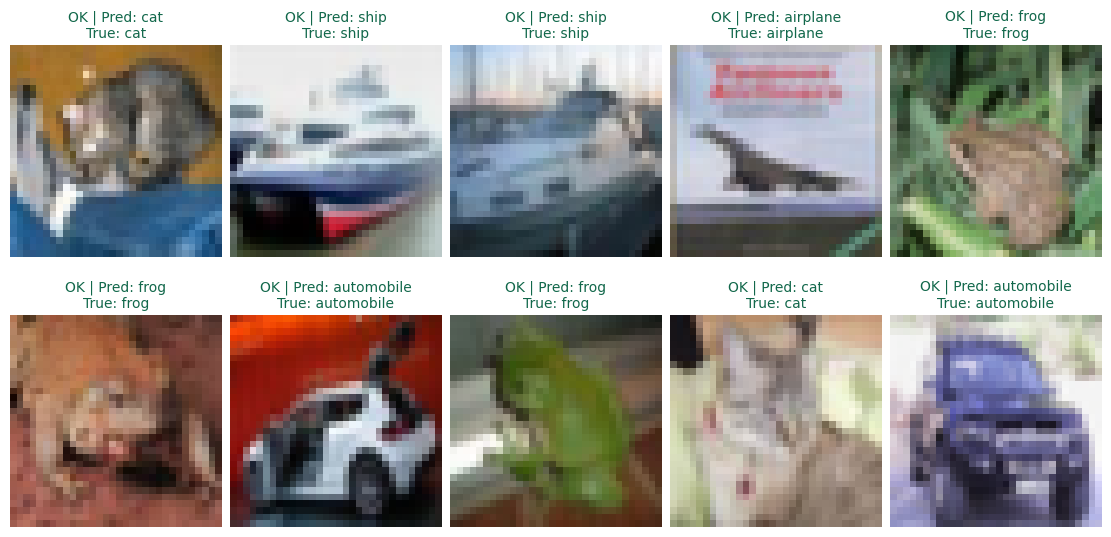

In [13]:
examples = [test_subset[index] for index in range(10)]  # 用列表推导式取测试子集的前 10 个样本；每个样本都是（图片张量, 真实标签）。
# stack 在最前面加一个批次维度：[3, 32, 32] → [10, 3, 32, 32]。
example_images = torch.stack([image for image, label in examples])  # 先取各样本的图片，再用 stack 增加批次维度，形状从单图 [3, 32, 32] 变为 [10, 3, 32, 32]。
model.eval()  # 切换为评估模式，使用训练后保存的 BatchNorm 运行统计量。
with torch.inference_mode():  # 在下面的缩进块中关闭梯度记录，执行预测。
    predicted_labels = model(example_images.to(device)).argmax(dim=1).tolist()  # 把图片移到设备并计算分数，再取最大分数对应的类别；tolist() 将结果转为 Python 列表。

fig, axes = plt.subplots(2, 5, figsize=(11, 5.4), layout="constrained")  # 创建 2 行 5 列子图，容纳这 10 张图片，自动调整间距。
for axis, (image, true_label), pred_label in zip(axes.flat, examples, predicted_labels):  # zip 把子图、样本和预测逐个配对；嵌套拆包取得当前图片、真实标签及预测标签。
    is_correct = pred_label == true_label  # 比较预测标签和真实标签，结果是 True 或 False。
    result = "OK" if is_correct else "MISS"  # 条件表达式：预测正确时显示 OK，否则显示 MISS。
    axis.imshow(image.permute(1, 2, 0))  # 调整通道顺序后显示当前图片，使其符合 Matplotlib 的输入格式。
    axis.set_title(  # 设置当前子图的标题，具体文字和样式在下面几行指定。
        f"{result} | Pred: {class_names[pred_label]}\nTrue: {class_names[true_label]}",  # 通过类别索引查名称；字符串中的换行符让预测类别和真实类别分成两行。
        color="#12684b" if is_correct else "#9b3028",  # 根据预测是否正确选择颜色：正确用绿色，错误用红色。
        fontsize=10,  # 把标题字号设为 10，便于在多个子图中阅读。
    )  # 结束标题设置函数调用。
    axis.axis("off")  # 隐藏坐标轴和刻度，让注意力集中在图片和预测结果上。
plt.show()  # 显示全部 10 张图片及对应的预测结果。

## 7. 动手改一处

1. **练 Python 索引：** 在第 2 节把 `labels[0]` 改成 `labels[1]`。先猜会打印哪张图的标签，然后执行验证。
2. **练看张量形状：** 在第 3 节把 `example` 的第一维改成 2，预测输出形状，也修改 `assert` 的期望值。
3. **练做实验：** 记录默认结果，然后只把快速模式的 `num_epochs` 从 3 改成 5。重启内核并从头运行，比较训练损失和测试准确率。这里轮数也会改变学习率曲线的长度，所以比较的是两套训练计划。
4. **练效率思维：** 分别记录快速和课程模式的参数量、MACs。只运行到第 3 节就能比较，不必等待完整训练。为什么两个模型都输出 10 个分数，计算量却不同？